# Measuring Uncertainty in Finite Samples

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`.

The first statement gives a large-sample normal approximation; the second gives the simulation error of an average:

$$
\sqrt n\,(\widehat\theta_n-\theta)\Rightarrow\mathcal N(0,V),
\qquad
\operatorname{SE}(\overline Z_M)=\frac{s_Z}{\sqrt M}.
$$

Here, $n$ is sample size; $\widehat\theta_n$ estimates $\theta$; $V$ is the limiting variance; $\Rightarrow$ denotes convergence in distribution. $M$ is the number of simulation runs; $\overline Z_M$ is their average; $s_Z$ is their sample standard deviation; $\operatorname{SE}$ is standard error.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("01_mathematical_language");


## Monte Carlo Design

The equations estimate average error and root mean squared error across repeated samples:

$$
\widehat b_M=\frac{1}{M}\sum_{m=1}^{M}(\widehat\theta^{(m)}-\theta),
\qquad
\widehat{\operatorname{RMSE}}_M=
\left[\frac{1}{M}\sum_{m=1}^{M}\lVert\widehat\theta^{(m)}-\theta\rVert^2\right]^{1/2}.
$$

Here, $M$ is the number of repetitions; $m$ labels a repetition; $\widehat\theta^{(m)}$ is its estimate; $\theta$ is the true target. $\widehat b_M$ is estimated bias; $\widehat{\operatorname{RMSE}}_M$ is estimated root mean squared error; $\lVert\cdot\rVert$ is a vector or matrix norm.

In [2]:
population_mean, population_covariance = RiskLabAI.Data.form_true_matrix(3, 2, .65; rng=Xoshiro(20260925))
population_weights = minimum_variance_weights(population_covariance)
minimum_risk = dot(population_weights, population_covariance*population_weights)
sample_sizes = [40, 80, 160, 320, 640, 1280]
repetitions = 240
simulation_generator = Xoshiro(20260927)
records = NamedTuple[]
for sample_size in sample_sizes, repetition in 1:repetitions
    estimated_mean, estimated_covariance = RiskLabAI.Data.simulates_cov_mu(population_mean, population_covariance, sample_size; shrink=false, rng=simulation_generator)
    estimated_weights = minimum_variance_weights(estimated_covariance)
    estimated_risk = dot(estimated_weights, population_covariance*estimated_weights)
    push!(records, (; sample_size, mean_error=norm(estimated_mean-population_mean), covariance_error=norm(estimated_covariance-population_covariance)/norm(population_covariance), risk_inflation=estimated_risk/minimum_risk-1))
end
simulation_results = DataFrame(records)
rename!(simulation_results, ["Sample size", "Mean error", "Relative covariance error", "Risk inflation"])
save_data(simulation_results, paths, "finite_sample_repetitions")
finite_sample_summary = combine(groupby(simulation_results, "Sample size"; sort=true), "Mean error"=>median=>"Median mean error", "Relative covariance error"=>median=>"Median relative covariance error", "Risk inflation"=>median=>"Median risk inflation", "Risk inflation"=>(values->quantile(values, .90))=>"Risk inflation 90th percentile")
save_table(finite_sample_summary, paths, "finite_sample_summary"; caption="Monte Carlo errors and portfolio risk inflation by sample size.", label="tab:finite-sample-summary")


Row,Sample size,Median mean error,Median relative covariance error,Median risk inflation,Risk inflation 90th percentile
,Int64,Float64,Float64,Float64,Float64
1,40,0.0441751,0.275577,0.114233,0.281572
2,80,0.0323803,0.200698,0.0595759,0.122913
3,160,0.0219696,0.141413,0.03056,0.0659335
4,320,0.0157113,0.0996028,0.01271,0.0290211
5,640,0.0113427,0.0670936,0.00697631,0.0133243
6,1280,0.00808955,0.0493835,0.00350364,0.00686433


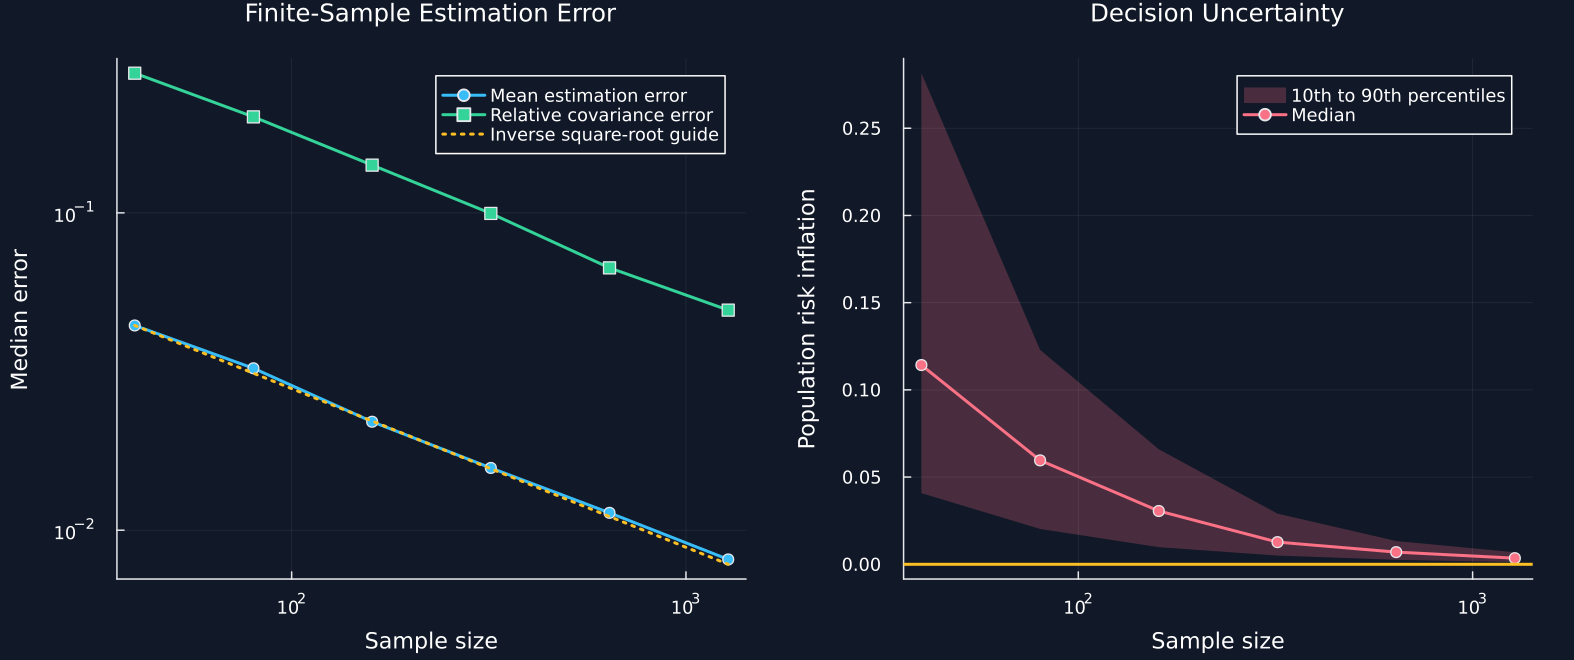

In [3]:
reference_rate = finite_sample_summary[1, "Median mean error"].*sqrt.(sample_sizes[1]./sample_sizes)
risk_quantiles = combine(groupby(simulation_results, "Sample size"; sort=true), "Risk inflation"=>(values->quantile(values, .10))=>"lower", "Risk inflation"=>median=>"median", "Risk inflation"=>(values->quantile(values, .90))=>"upper")
finite_sample_figure_data = DataFrame("Sample size"=>sample_sizes, "Median mean error"=>finite_sample_summary[!, "Median mean error"], "Median relative covariance error"=>finite_sample_summary[!, "Median relative covariance error"], "Inverse square-root guide"=>reference_rate, "Risk inflation 10th percentile"=>risk_quantiles.lower, "Median risk inflation"=>risk_quantiles.median, "Risk inflation 90th percentile"=>risk_quantiles.upper)
save_data(finite_sample_figure_data, paths, "finite_sample_convergence")
error_panel = plot(sample_sizes, finite_sample_summary[!, "Median mean error"]; xscale=:log10, yscale=:log10, marker=:circle, color=palette.cyan, label="Mean estimation error", xlabel="Sample size", ylabel="Median error", title="Finite-Sample Estimation Error")
plot!(error_panel, sample_sizes, finite_sample_summary[!, "Median relative covariance error"]; marker=:square, color=palette.green, label="Relative covariance error")
plot!(error_panel, sample_sizes, reference_rate; color=palette.amber, linestyle=:dot, label="Inverse square-root guide")
risk_panel = plot(sample_sizes, risk_quantiles.lower; fillrange=risk_quantiles.upper, fillalpha=.24, linealpha=0, color=palette.rose, xscale=:log10, label="10th to 90th percentiles", xlabel="Sample size", ylabel="Population risk inflation", title="Decision Uncertainty")
plot!(risk_panel, sample_sizes, risk_quantiles.median; marker=:circle, color=palette.rose, label="Median")
hline!(risk_panel, [0.]; color=palette.amber, label="")
figure = plot(error_panel, risk_panel; layout=(1, 2), size=(1050, 440))
save_figure(figure, paths, "finite_sample_convergence")


## Numerical Tolerance

The scaled error of a computed linear-system solution should be small relative to rounding error and problem difficulty:

$$
\frac{\lVert A\widehat x-b\rVert_2}{\lVert A\rVert_2\lVert\widehat x\rVert_2+\lVert b\rVert_2}
\leq C\,\varepsilon_{\mathrm{mach}}\,\kappa_2(A).
$$

Here, $A$ is the coefficient matrix; $\widehat x$ is the computed solution; $b$ is the right-hand side. $\lVert\cdot\rVert_2$ is the Euclidean or spectral norm; $C$ is a chosen safety factor; $\varepsilon_{\mathrm{mach}}$ is machine precision. $\kappa_2(A)$ is the condition number of $A$ in the spectral norm.

Row,Condition number,Scaled residual,Tolerance
,Float64,Float64,Float64
1,10.0,3.42854e-17,2.22045e-13
2,1000.0,6.54556e-17,2.22045e-11
3,100000.0,4.97804e-17,2.22045e-9
4,1.0e7,5.04234e-17,2.22045e-7
5,1.0e9,3.22759e-17,2.22045e-5


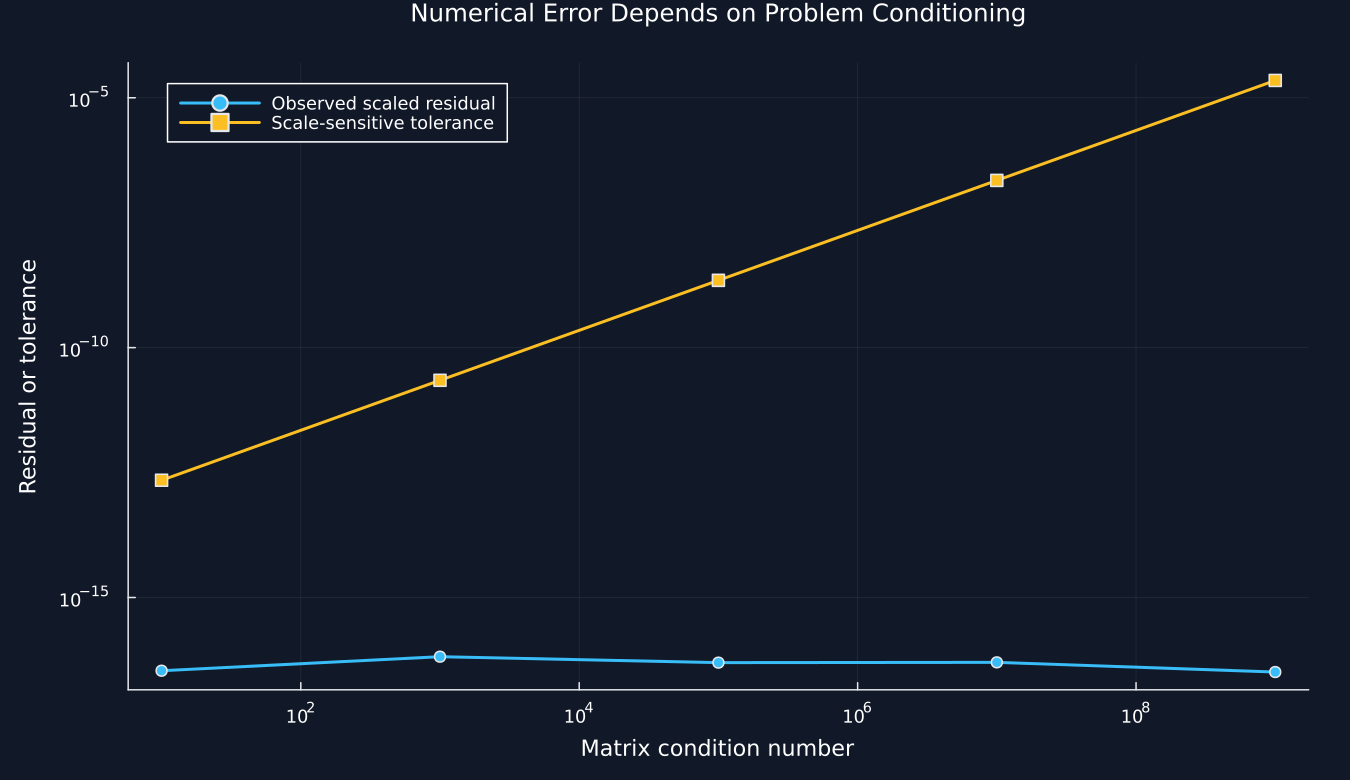

In [4]:
tolerance_generator = Xoshiro(20260928)
orthogonal_matrix = Matrix(qr(randn(tolerance_generator, 6, 6)).Q)
condition_numbers = [1e1, 1e3, 1e5, 1e7, 1e9]
right_hand_side = ones(6)
machine_epsilon = eps(Float64)
tolerance_records = NamedTuple[]
for condition_number in condition_numbers
    eigenvalues = exp.(range(0., -log(condition_number); length=6))
    matrix = orthogonal_matrix*Diagonal(eigenvalues)*orthogonal_matrix'
    solution = matrix\right_hand_side
    residual = norm(matrix*solution-right_hand_side)
    scaled_residual = residual/(opnorm(matrix)*norm(solution)+norm(right_hand_side))
    tolerance = 100*machine_epsilon*cond(matrix)
    push!(tolerance_records, (; condition_number=cond(matrix), scaled_residual, tolerance))
end
numerical_tolerance = DataFrame(tolerance_records)
rename!(numerical_tolerance, ["Condition number", "Scaled residual", "Tolerance"])
save_data(numerical_tolerance, paths, "numerical_tolerance")
save_table(numerical_tolerance, paths, "numerical_tolerance"; caption="Scale-sensitive numerical tolerances for linear systems with increasing condition numbers.", label="tab:numerical-tolerance")
plotted_residual = max.(numerical_tolerance[!, "Scaled residual"], floatmin(Float64))
figure = plot(numerical_tolerance[!, "Condition number"], plotted_residual; xscale=:log10, yscale=:log10, marker=:circle, color=palette.cyan, label="Observed scaled residual", xlabel="Matrix condition number", ylabel="Residual or tolerance", title="Numerical Error Depends on Problem Conditioning", legend=:topleft, size=(900, 520))
plot!(figure, numerical_tolerance[!, "Condition number"], numerical_tolerance.Tolerance; marker=:square, color=palette.amber, label="Scale-sensitive tolerance")
save_figure(figure, paths, "numerical_tolerance")


## Tests

In [5]:
reproducible_mean_a, reproducible_covariance_a = RiskLabAI.Data.simulates_cov_mu(population_mean, population_covariance, 80; shrink=false, rng=Xoshiro(271828))
reproducible_mean_b, reproducible_covariance_b = RiskLabAI.Data.simulates_cov_mu(population_mean, population_covariance, 80; shrink=false, rng=Xoshiro(271828))
@assert reproducible_mean_a == reproducible_mean_b
@assert reproducible_covariance_a == reproducible_covariance_b
@assert nrow(simulation_results) == length(sample_sizes)*repetitions
@assert finite_sample_summary[end, "Median mean error"] < finite_sample_summary[1, "Median mean error"]
@assert finite_sample_summary[end, "Median relative covariance error"] < finite_sample_summary[1, "Median relative covariance error"]
@assert finite_sample_summary[end, "Median risk inflation"] < finite_sample_summary[1, "Median risk inflation"]
@assert all(simulation_results[!, "Risk inflation"] .>= -1e-10)
@assert all(numerical_tolerance[!, "Scaled residual"] .<= numerical_tolerance.Tolerance)
@assert all(diff(numerical_tolerance[!, "Condition number"]) .> 0)
